In [1]:
from reasoning_aware_irt.toy_scenarios import make_reasoning_aware_3pl_toy, build_scenarios

In [2]:
toy_list, names = build_scenarios()
print(names, len(toy_list))

['fail_budget_leverage_items', 'fail_budget_response', 'fail_confounding', 'fail_effective_rank', 'fail_fisher_proxy', 'fail_variance_ceiling', 'fail_variance_floor', 'pass_all'] 8


In [3]:
from reasoning_aware_irt.precondition_check import DataPreChecker
import numpy as np

avg_Y_list = [float(np.mean(t['Y_ij'])) for t in toy_list]

# results_list = []
passes = []
warns = []
all_results = {}
for i, toy in enumerate(toy_list):
    print('\n', names[i])
    chk = DataPreChecker(Y_ij=toy['Y_ij'], B_ij=toy['B_ij'], P_ij=toy.get('P_ij'))
    ok, warn, res = chk.run_all_tests()
    all_results[names[i]] = res
    # results_list.append(res)
    passes.append(ok)
    warns.append(warn)


print("passes:", passes)
print("warns:", warns)


 fail_budget_leverage_items
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[FAIL] Budget Leverage: Items OK=0.20, Models OK=1.00
[PASS] Effective Rank=30.50, Ratio=0.94
[PASS] Ability-Budget Confounding Corr=-0.1017
[WARN] Budget-Response Association: Signal Prop=0.055 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.125 with threshold=0.23

 fail_budget_response
[PASS] Variance/Entropy: Items=0.81, Models=1.00
[PASS] Fisher Proxy: Items=0.1965, Models=0.2319
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=46.16, Ratio=0.95
[PASS] Ability-Budget Confounding Corr=-0.0919
[PASS] Budget-Response Association: Signal Prop=0.120 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.105 with threshold=0.23

 fail_confounding
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] 

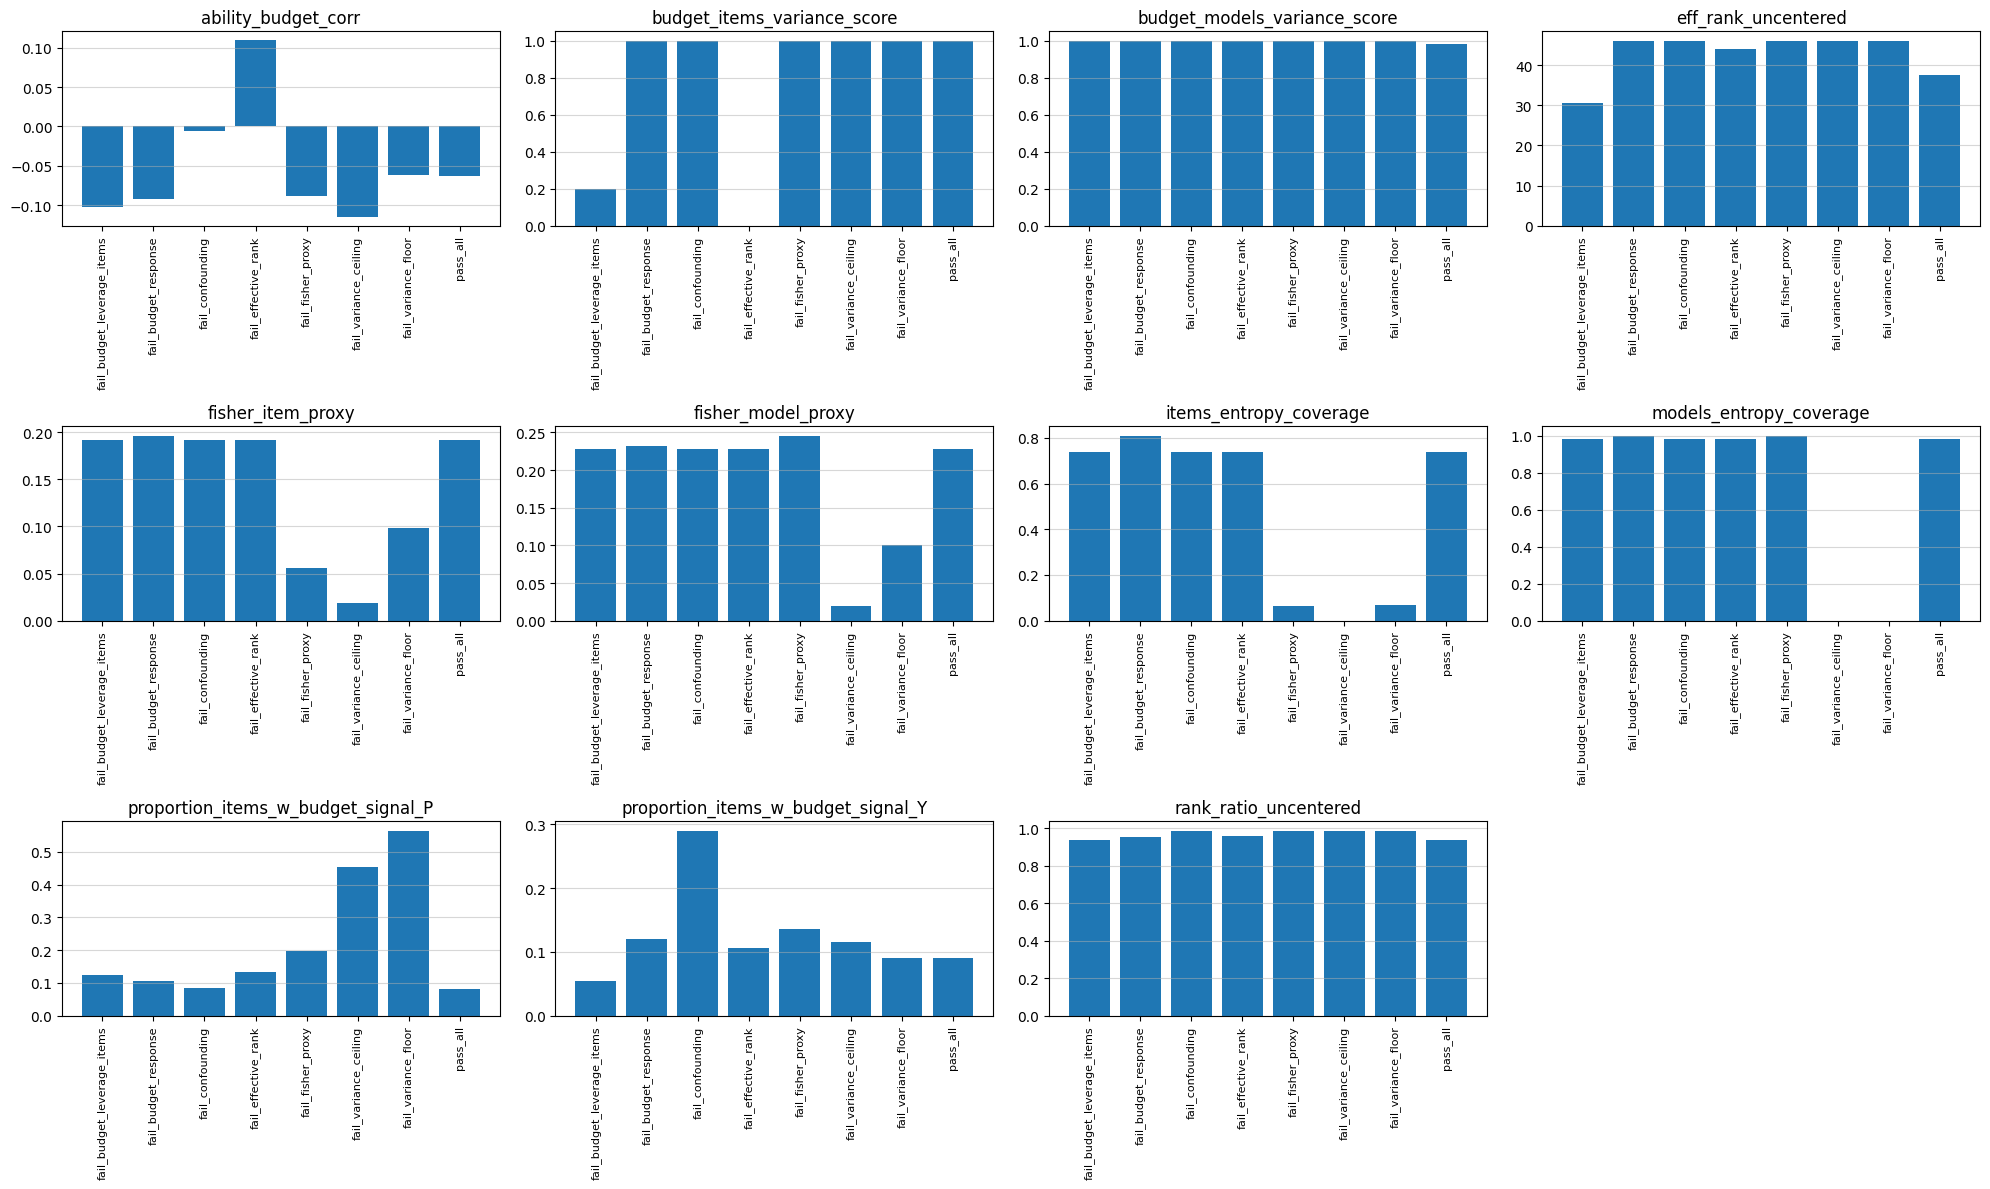

In [4]:
from reasoning_aware_irt.precondition_check import plot_precheck_results
import matplotlib.pyplot as plt
# fig, _ = plot_precheck_results(results_list, titles=names, avg_Y_list=avg_Y_list)
fig, _ = plot_precheck_results(all_results)
plt.show() # enable when running as a script

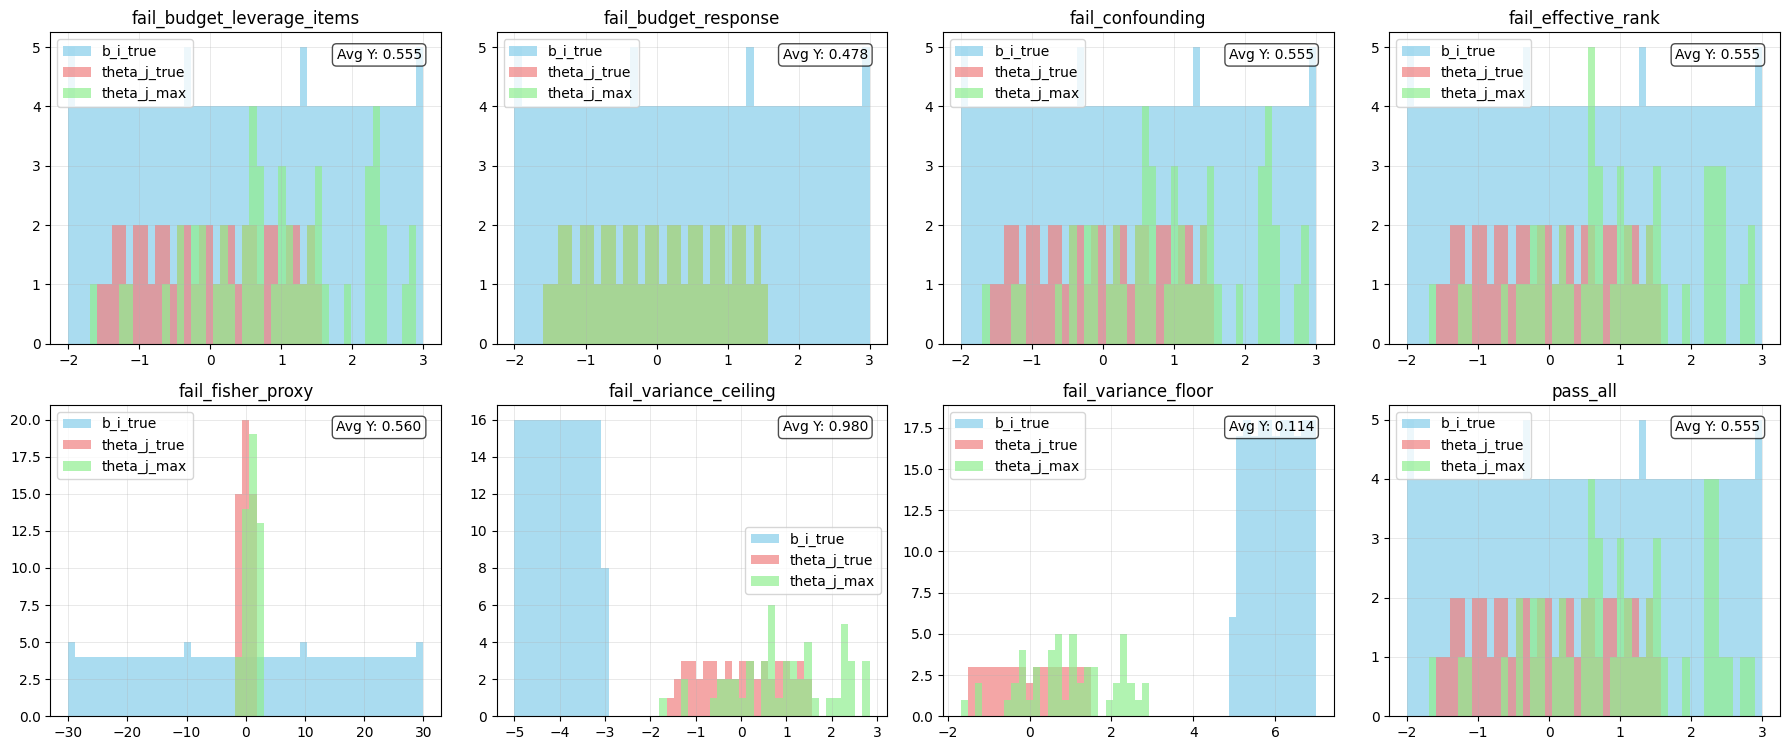

In [5]:
from reasoning_aware_irt.utils import plot_multiple_b_theta_histograms
_, _ = plot_multiple_b_theta_histograms(toy_list, names, plots_per_row=4, avg_Y_list=avg_Y_list)

# Systematic Check - varying #gate-on

In [ ]:
print_msg = False

b_span_list = np.linspace(-2.0, 5, 10)

toy_data_name_list, toy_data_list = [], []
all_results = []
avg_Y_list = []
for b_span in b_span_list:
    toy_data = make_reasoning_aware_3pl_toy(b_span_low=  b_span,
                                           b_span_high= b_span+1,
                                           frac_gate_on=1.0
                                           )
    toy_data_list.append(toy_data)
    toy_data_name_list.append(str(b_span))

    Y_mean = toy_data['Y_ij'].mean()
    avg_Y_list.append(Y_mean)

    if print_msg:
        print(f"\n--- RUNNING b_span: {b_span} ---")
        print(f"Average of Y = {Y_mean}")

    checker = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data['P_ij'], print_msg=print_msg)
    ok, warn, results = checker.run_all_tests()
    all_results.append(results)

In [ ]:
_, _ = plot_multiple_b_theta_histograms(toy_data_list, toy_data_name_list, plots_per_row=4, avg_Y_list=avg_Y_list)

In [ ]:
_,_ = plot_precheck_results(all_results)

# GEM

0.43915


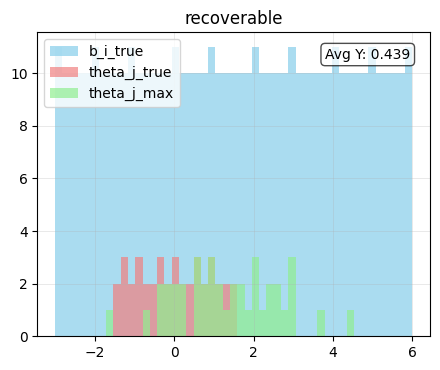

In [6]:
toy_data = make_reasoning_aware_3pl_toy(Q=500, c_val=0.01, 
                                        b_span_low=  -3, b_span_high= 6,frac_gate_on=0.8)

print(toy_data['Y_ij'].mean())
_, _ = plot_multiple_b_theta_histograms([toy_data], ['recoverable'], plots_per_row=2, avg_Y_list=[toy_data['Y_ij'].mean()])

In [7]:
chk = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data.get('P_ij'))
ok, warn, res = chk.run_all_tests()

[PASS] Variance/Entropy: Items=0.41, Models=1.00
[PASS] Fisher Proxy: Items=0.1299, Models=0.2336
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=38.33, Ratio=0.99
[PASS] Ability-Budget Confounding Corr=-0.0789
[PASS] Budget-Response Association: Signal Prop=0.258 with threshold=0.26
[PASS] Budget-Response with PROB: Signal Prop=0.696 with threshold=0.26


In [ ]:
from reasoning_aware_irt.gem import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem import ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=toy_data["Y_ij"], B_ij=toy_data["B_ij"], c_i=toy_data["c_i_true"])
cfg = CalibrationConfig(
    gh_nodes=21, max_outer=100, verbose=True
)

calibrator = ReasoningAware3PLCalibrator(cfg)


In [9]:
fit_results = calibrator.fit(data)

iter   1  ll=-7342.986590   dLL=nan
iter   2  ll=-6755.018439   dLL=nan
iter   3  ll=-6493.364290   dLL=2.617e+02
iter   4  ll=-6436.364711   dLL=5.700e+01
iter   5  ll=-6413.644088   dLL=2.272e+01
iter   6  ll=-6400.245495   dLL=1.340e+01
iter   7  ll=-6392.655381   dLL=7.590e+00
iter   8  ll=-6387.097173   dLL=5.558e+00
iter   9  ll=-6382.641537   dLL=4.456e+00
iter  10  ll=-6379.103679   dLL=3.538e+00
iter  11  ll=-6376.142375   dLL=2.961e+00
iter  12  ll=-6373.286985   dLL=2.855e+00
iter  13  ll=-6370.660127   dLL=2.627e+00
iter  14  ll=-6368.269609   dLL=2.391e+00
iter  15  ll=-6365.946619   dLL=2.323e+00
iter  16  ll=-6363.883181   dLL=2.063e+00
iter  17  ll=-6361.751150   dLL=2.132e+00
iter  18  ll=-6359.953399   dLL=1.798e+00
iter  19  ll=-6358.043956   dLL=1.909e+00
iter  20  ll=-6355.691778   dLL=2.352e+00
iter  21  ll=-6350.003636   dLL=5.688e+00
iter  22  ll=-6343.133295   dLL=6.870e+00
iter  23  ll=-6341.648154   dLL=1.485e+00
iter  24  ll=-6340.956559   dLL=6.916e-01
iter

In [ ]:
# fit_results.gamma_j = np.clip(fit_results.gamma_j, -1, 1)

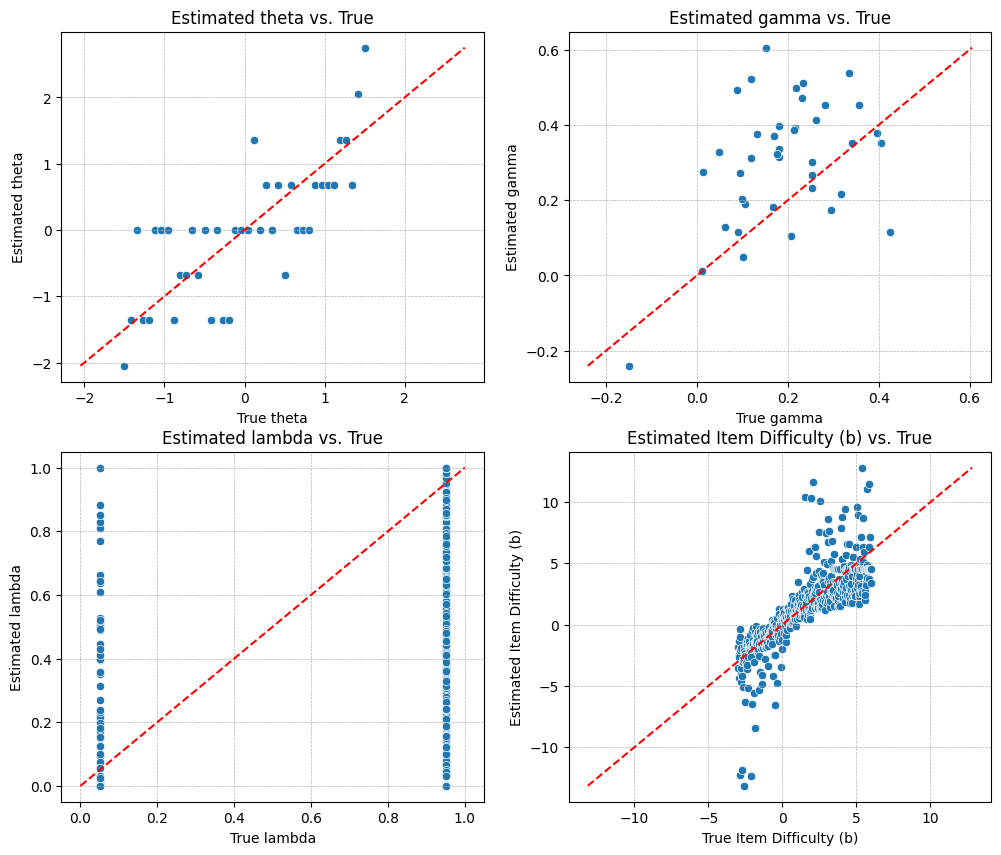

In [11]:
import seaborn as sns

def plot_parameter_scatter(ax, true_values, estimated_values, param_name, param_label):
    """Generates a scatter plot of estimated vs true parameter values."""
    sns.scatterplot(x=true_values, y=estimated_values, ax=ax)
    ax.set_title(f'Estimated {param_label} vs. True')
    ax.set_xlabel(f'True {param_label}')
    ax.set_ylabel(f'Estimated {param_label}')
    min_val = min(true_values.min(), estimated_values.min())
    max_val = max(true_values.max(), estimated_values.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

plot_parameter_scatter(axes[0], toy_data["theta_j_true"], fit_results.theta_j_mean, "theta", "theta")
plot_parameter_scatter(axes[1], toy_data["gamma_j_true"], fit_results.gamma_j, "gamma", "gamma")
plot_parameter_scatter(axes[2], toy_data["lambda_i_true"], fit_results.lambda_i, "lambda", "lambda")
plot_parameter_scatter(axes[3], toy_data["b_i_true"], fit_results.b_i, "b", "Item Difficulty (b)")

In [15]:
import seaborn as sns
import numpy as np
from typing import Union, List
from matplotlib.axes import Axes

def plot_parameter_scatter_with_se(
    ax: Axes,
    true_values: Union[np.ndarray, List[float]],
    estimated_values: Union[np.ndarray, List[float]],
    estimated_se: Union[np.ndarray, List[float]],  # <--- New Argument
    param_name: str,
    param_label: str
):
    """
    Generates a scatter plot of estimated vs true parameter values,
    including standard error (SE) bars on the estimated values (Y-axis).
    """
    # 1. Plot the Central Estimates (Scatter Plot)
    # We use ax.scatter instead of sns.scatterplot here because we'll add
    # error bars in a separate layer, often simplifying the control.
    ax.scatter(x=true_values, y=estimated_values, label='Estimate', color='blue', alpha=0.6, s=20)

    # 2. Add Error Bars based on estimated_se
    # The 'yerr' argument takes the standard error (or range) for the vertical axis (estimated values).
    # We plot the error bars without re-plotting the central point (fmt='none').
    ax.errorbar(
        x=true_values,
        y=estimated_values,
        yerr=estimated_se, # <-- Key addition: Estimated SE provides the error distance
        fmt='none',       # Do not plot the data points again
        ecolor='gray',    # Error bar color
        elinewidth=0.8,   # Error bar line thickness
        capsize=3,        # Size of the caps on the error bars
        alpha=0.5,        # Transparency
        zorder=0          # Ensure error bars are plotted underneath the central points
    )

    # 3. Set Labels, Title, and 1:1 Line (Unchanged)
    ax.set_title(f'Estimated {param_label} vs. True')
    ax.set_xlabel(f'True {param_label}')
    ax.set_ylabel(f'Estimated {param_label} (with SE)')

    # Calculate global min/max for the 1:1 line and axis limits
    # We should consider the full range of the error bars for robust axis limits
    min_data = min(true_values.min(), (estimated_values - estimated_se).min())
    max_data = max(true_values.max(), (estimated_values + estimated_se).max())

    # Add a small buffer for visualization
    buffer = (max_data - min_data) * 0.05
    min_val = min_data - buffer
    max_val = max_data + buffer

    # Plot the 1:1 reference line
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='1:1 Line')

    # Set axis limits based on buffered min/max
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)

    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax.legend()


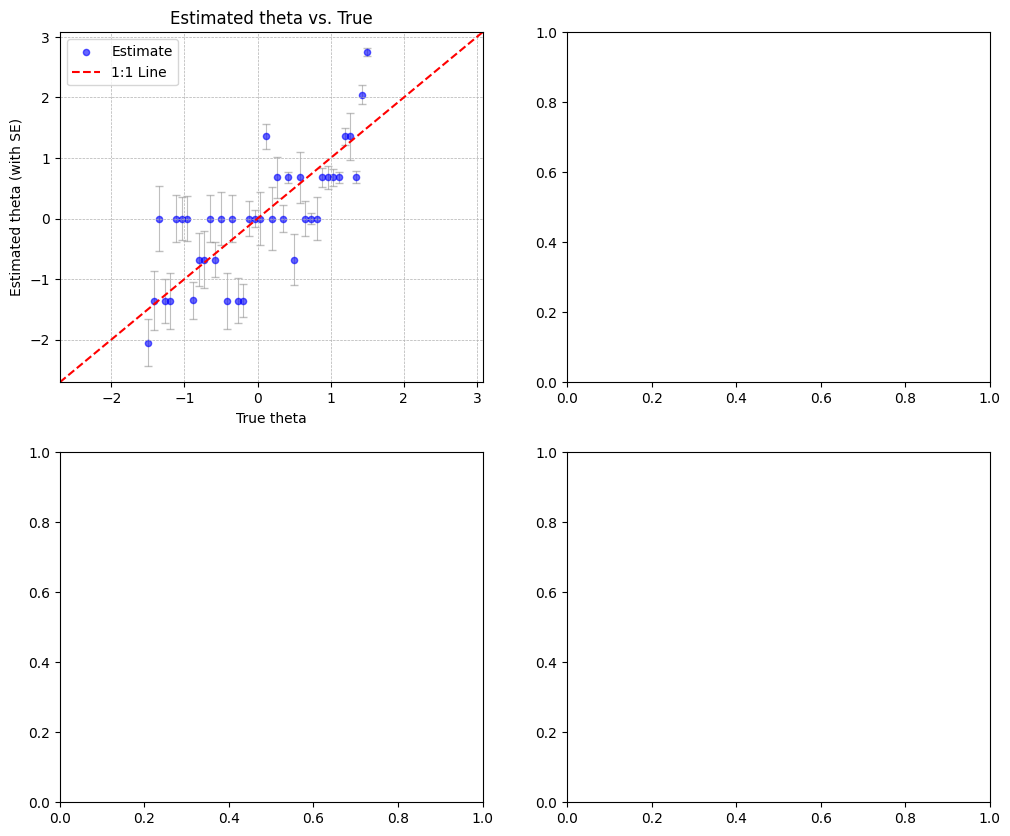

In [19]:
# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

plot_parameter_scatter_with_se(axes[0], toy_data["theta_j_true"], fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta", "theta")
# plot_parameter_scatter(axes[1], toy_data["gamma_j_true"], fit_results.gamma_j, "gamma", "gamma")
# plot_parameter_scatter(axes[2], toy_data["lambda_i_true"], fit_results.lambda_i, "lambda", "lambda")
# plot_parameter_scatter(axes[3], toy_data["b_i_true"], fit_results.b_i, "b", "Item Difficulty (b)")

# Macro Information Function

In [ ]:
from reasoning_aware_irt.utils import create_test_information_figure, create_item_information_figure, plot_test_characteristic_curve

item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_test_information_figure(a,b,c,item_names)


In [ ]:
fig.show()

In [ ]:
item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_item_information_figure(a,b,c,item_names)
fig.show()

In [ ]:
fig = plot_test_characteristic_curve(toy_data_list[2])
fig.show()